In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time
import joblib

from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import QuantileTransformer

import optuna
import shap

import random
from heapq import nsmallest

In [10]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [11]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
}

In [12]:
# Fix random state
random_state = 42

In [13]:
harps = pd.read_csv('harps_final_for_feh.csv')
apogee = pd.read_csv('apogee_final_for_feh.csv')
galah = pd.read_csv('galah_final_for_feh.csv')


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')

harps contains 798 stars
apogee contains 45727 stars
galah contains 71591 stars


### Spliting data into Trianing and Testing sets

In [14]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']
X_apogee = apogee.drop(columns=['fe_h'])
y_apogee = apogee['fe_h']
X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.1, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']
X_galah = galah.drop(columns=['fe_h'])
y_galah = galah['fe_h']
X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']


# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train], ignore_index=True)

# Combine APOGEE and GALAH sets
X_combined = pd.concat([X_apogee, X_galah], ignore_index=True)
y_combined = pd.concat([y_apogee, y_galah], ignore_index=True)

full_df = pd.concat([apogee, galah, harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [15]:
best_lgbm = joblib.load("best_lgbm.pkl")
best_cat = joblib.load("best_cat.pkl")
best_xgb = joblib.load("best_xgb.pkl")


### Core utilities (labels + output folder)

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score, KFold

# Your mapping (use yours or the refined one)
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
}

def ensure_dir(path: str) -> None:
    os.makedirs(path, exist_ok=True)

def pretty_feature_names(cols, label_map=PRETTY_LABELS):
    return [label_map.get(c, c) for c in cols]

def save_series_csv(series: pd.Series, out_csv: str, label_map=PRETTY_LABELS):
    df = series.rename("value").to_frame()
    df["feature"] = df.index
    df["pretty"] = [label_map.get(c, c) for c in df.index]
    df = df[["feature", "pretty", "value"]]
    df.to_csv(out_csv, index=False)

### Plot helper (publication-style horizontal bars)

In [17]:
def plot_barh_series(
    series: pd.Series,
    title: str,
    xlabel: str,
    outpath: str,
    label_map=PRETTY_LABELS,
    figsize=(8, 6),
    top_n=None
):
    s = series.copy().dropna()

    if top_n is not None:
        s = s.sort_values(ascending=False).head(top_n).sort_values(ascending=True)
    else:
        s = s.sort_values(ascending=True)

    labels = pretty_feature_names(s.index, label_map)

    plt.figure(figsize=figsize)
    plt.barh(labels, s.values)
    plt.xlabel(xlabel)
    plt.title(title)
    plt.tight_layout()

    plt.savefig(outpath, dpi=300)
    plt.close()

## Built-in importance (gain/weight) for different models

In [18]:
def builtin_importance(model, X: pd.DataFrame, importance_type="gain") -> pd.Series:
    """
    Returns a pd.Series indexed by feature names.
    Tries to handle: LightGBM, XGBoost, CatBoost (if available), generic sklearn.
    """
    cols = X.columns

    # LightGBM sklearn API
    if hasattr(model, "booster_"):
        booster = model.booster_
        imp = booster.feature_importance(importance_type=importance_type)
        return pd.Series(imp, index=cols)

    # XGBoost sklearn API: feature_importances_ often exists (importance_type depends on how trained)
    if hasattr(model, "get_booster"):
        # Prefer booster score if possible
        booster = model.get_booster()
        try:
            score_dict = booster.get_score(importance_type=importance_type)
            # XGBoost uses f0, f1... unless feature_names were passed; map robustly:
            out = pd.Series(0.0, index=cols)
            for k, v in score_dict.items():
                if k in cols:
                    out[k] = v
                elif k.startswith("f"):
                    idx = int(k[1:])
                    if idx < len(cols):
                        out.iloc[idx] = v
            return out
        except Exception:
            pass

    # Generic sklearn-style
    if hasattr(model, "feature_importances_"):
        return pd.Series(getattr(model, "feature_importances_"), index=cols)

    # CatBoost has get_feature_importance
    if hasattr(model, "get_feature_importance"):
        try:
            imp = model.get_feature_importance()
            return pd.Series(imp, index=cols)
        except Exception:
            pass

    raise ValueError("Model does not expose a built-in feature importance method.")

## Permutation importance (ΔRMSE)

In [19]:
def permutation_importance_rmse(
    model,
    X: pd.DataFrame,
    y,
    n_repeats=20,
    random_state=42,
    n_jobs=-1
) -> pd.Series:
    """
    Returns +ΔRMSE (higher = more important).
    """
    perm = permutation_importance(
        model,
        X,
        y,
        n_repeats=n_repeats,
        random_state=random_state,
        n_jobs=n_jobs,
        scoring="neg_root_mean_squared_error"
    )
    delta_rmse = -perm.importances_mean  # negate because score is negative RMSE
    return pd.Series(delta_rmse, index=X.columns)

## SHAP global importance + optional SHAP summary plot

In [ ]:
def shap_global_importance(
    model,
    X: pd.DataFrame,
    outdir: str,
    model_name: str,
    label_map=PRETTY_LABELS,
    make_summary_plot=True,
    max_display=20,
    random_state=42
) -> pd.Series:
    """
    Computes mean(|SHAP|) per feature and optionally saves a SHAP summary plot.
    Works best with tree models. For speed, you can pass a subsample of X.
    """

    ensure_dir(outdir)

    # Use TreeExplainer for tree ensembles; fallback to Explainer
    try:
        explainer = shap.TreeExplainer(model)
    except Exception:
        explainer = shap.Explainer(model, X)

    shap_values = explainer(X)

    # shap_values.values shape: (n_samples, n_features)
    vals = shap_values.values
    if vals.ndim == 3:  # sometimes multioutput; take first output
        vals = vals[:, :, 0]

    mean_abs = np.abs(vals).mean(axis=0)
    s = pd.Series(mean_abs, index=X.columns)

    if make_summary_plot:
        # Replace feature names with pretty labels in the plot
        X_plot = X.copy()
        X_plot.columns = [label_map.get(c, c) for c in X.columns]

        plt.figure()
        shap.summary_plot(
            vals,
            X_plot,
            show=False,
            max_display=max_display
        )
        outpath = os.path.join(outdir, f"{model_name}_shap_summary.png")
        plt.tight_layout()
        plt.savefig(outpath, dpi=300, bbox_inches="tight")
        plt.close()

    return s

## Single-feature CV RMSE

In [21]:
def single_feature_cv_rmse(
    model,
    X: pd.DataFrame,
    y,
    cv=5,
    random_state=42
) -> pd.Series:
    """
    Trains the SAME model type using only one feature at a time (with CV),
    returns RMSE per feature (lower = better predictive power alone).
    """
    # Use deterministic splits
    if isinstance(cv, int):
        cv = KFold(n_splits=cv, shuffle=True, random_state=random_state)

    rmse = {}
    for col in X.columns:
        scores = cross_val_score(
            model,
            X[[col]],
            y,
            scoring="neg_root_mean_squared_error",
            cv=cv,
            n_jobs=-1
        )
        rmse[col] = -scores.mean()

    return pd.Series(rmse)

### One master function to run everything for a model

In [22]:
def run_feature_importance_suite(
    model,
    model_name: str,
    X: pd.DataFrame,
    y,
    outdir: str = "feature_importance_outputs",
    label_map=PRETTY_LABELS,
    top_n_plot=15,
    shap_subsample=None,  # int or None
):
    ensure_dir(outdir)

    results = {}

    # ---------- Built-in ----------
    try:
        bi = builtin_importance(model, X, importance_type="gain")
        bi = bi.sort_values(ascending=False)
        results["builtin_gain"] = bi

        save_series_csv(bi, os.path.join(outdir, f"{model_name}_builtin_gain.csv"), label_map)
        plot_barh_series(
            bi,
            title=f"{model_name}: Built-in importance (gain)",
            xlabel="Importance (relative units)",
            outpath=os.path.join(outdir, f"{model_name}_builtin_gain.png"),
            label_map=label_map,
            top_n=top_n_plot
        )
    except Exception as e:
        results["builtin_gain_error"] = str(e)

    # ---------- Permutation ----------
    perm = permutation_importance_rmse(model, X, y, n_repeats=20)
    perm = perm.sort_values(ascending=False)
    results["permutation_dRMSE"] = perm

    save_series_csv(perm, os.path.join(outdir, f"{model_name}_permutation_dRMSE.csv"), label_map)
    plot_barh_series(
        perm,
        title=f"{model_name}: Permutation importance",
        xlabel=r"$\Delta \mathrm{RMSE}$",
        outpath=os.path.join(outdir, f"{model_name}_permutation_dRMSE.png"),
        label_map=label_map,
        top_n=top_n_plot
    )

    # ---------- SHAP ----------
    X_shap = X
    if shap_subsample is not None and shap_subsample < len(X):
        X_shap = X.sample(shap_subsample, random_state=42)

    shap_dir = os.path.join(outdir, "shap")
    shap_imp = shap_global_importance(
        model,
        X_shap,
        outdir=shap_dir,
        model_name=model_name,
        label_map=label_map,
        make_summary_plot=True,
        max_display=top_n_plot
    )
    shap_imp = shap_imp.sort_values(ascending=False)
    results["shap_mean_abs"] = shap_imp

    save_series_csv(shap_imp, os.path.join(outdir, f"{model_name}_shap_meanabs.csv"), label_map)
    plot_barh_series(
        shap_imp,
        title=f"{model_name}: SHAP global importance",
        xlabel=r"Mean $|\mathrm{SHAP}|$",
        outpath=os.path.join(outdir, f"{model_name}_shap_meanabs.png"),
        label_map=label_map,
        top_n=top_n_plot
    )

    # ---------- Single-feature RMSE ----------
    # IMPORTANT: for CV single-feature, pass a *fresh clone* if your estimator mutates.
    # For most sklearn estimators, cross_val_score clones automatically.
    single_rmse = single_feature_cv_rmse(model, X, y, cv=5)
    single_rmse = single_rmse.sort_values(ascending=True)  # low RMSE is better
    results["single_feature_rmse"] = single_rmse

    save_series_csv(single_rmse, os.path.join(outdir, f"{model_name}_single_feature_rmse.csv"), label_map)
    plot_barh_series(
        single_rmse.sort_values(ascending=False),  # for plotting highest RMSE at top if desired
        title=f"{model_name}: Single-feature predictive power",
        xlabel="RMSE (single-feature CV)",
        outpath=os.path.join(outdir, f"{model_name}_single_feature_rmse.png"),
        label_map=label_map,
        top_n=top_n_plot
    )

    return results

In [23]:
all_results = {}

all_results["LGBM"] = run_feature_importance_suite(
    best_lgbm, "LGBM", X_apogee, y_apogee,
    outdir="featimp_outputs",
    shap_subsample=5000,     # speed-up; set None to use all
    top_n_plot=12
)

all_results["CatBoost"] = run_feature_importance_suite(
    best_cat, "CatBoost", X_apogee, y_apogee,
    outdir="featimp_outputs",
    shap_subsample=5000,
    top_n_plot=12
)

all_results["XGB"] = run_feature_importance_suite(
    best_xgb, "XGB", X_apogee, y_apogee,
    outdir="featimp_outputs",
    shap_subsample=5000,
    top_n_plot=12
)

In [43]:
# 1️⃣ Create explainer for the specific model
explainer_lgbm = shap.TreeExplainer(best_lgbm)

# 2️⃣ Compute SHAP values
shap_values_lgbm = explainer_lgbm.shap_values(X_apogee)

# Make the dependence plot
shap.dependence_plot(
    "zmax",
    shap_values_lgbm,
    X_apogee,
    interaction_index="rapo",
    show=False
)

# Replace labels manually
plt.xlabel(PRETTY_LABELS["zmax"])
plt.ylabel(r"SHAP value for $Z_{\max}$")

# Fix colorbar label
cb = plt.gcf().axes[-1]  # colorbar axis
cb.set_ylabel(PRETTY_LABELS["rapo"])

#plt.title(r"LGBM: SHAP dependence of $Z_{\max}$ colored by $R_{\mathrm{apo}}$")
plt.tight_layout()
plt.savefig("LGBM_zmax_rapo_dependence_pretty.png", dpi=300)
plt.close()

In [60]:
# 1️⃣ Create explainer for the specific model
explainer_lgbm = shap.TreeExplainer(best_lgbm)

# 2️⃣ Compute SHAP values
shap_values_lgbm = explainer_lgbm.shap_values(X_apogee)

# Make the dependence plot
shap.dependence_plot(
    "zmax",
    shap_values_lgbm,
    X_apogee,
    interaction_index="P_gal",
    show=False
)

# Replace labels manually
plt.xlabel(PRETTY_LABELS["zmax"])
plt.ylabel(r"SHAP value for $Z_{\max}$")

# Fix colorbar label
cb = plt.gcf().axes[-1]  # colorbar axis
cb.set_ylabel(PRETTY_LABELS["P_gal"])

#plt.title(r"LGBM: SHAP dependence of $Z_{\max}$ colored by $P_{\mathrm{gal}}$")
plt.tight_layout()
plt.savefig("LGBM_zmax_pgal_dependence_pretty.png", dpi=300)
plt.close()

In [49]:
# 1️⃣ Create explainer for the specific model
explainer_lgbm = shap.TreeExplainer(best_lgbm)

# 2️⃣ Compute SHAP values
shap_values_lgbm = explainer_lgbm.shap_values(X_harps)

# Make the dependence plot
shap.dependence_plot(
    "zmax",
    shap_values_lgbm,
    X_harps,
    interaction_index="rapo",
    show=False
)

# Replace labels manually
plt.xlabel(PRETTY_LABELS["zmax"])
plt.ylabel(r"SHAP value for $Z_{\max}$")

# Fix colorbar label
cb = plt.gcf().axes[-1]  # colorbar axis
cb.set_ylabel(PRETTY_LABELS["rapo"])

#plt.title(r"LGBM: SHAP dependence of $Z_{\max}$ colored by $R_{\mathrm{apo}}$")
plt.tight_layout()
plt.savefig("LGBM_zmax_rapo_dependence_pretty_harps.png", dpi=300)
plt.close()

In [44]:
for name in ["LGBM", "CatBoost", "XGB"]:
    top = all_results[name]["permutation_dRMSE"].head(2)
    print(name)
    print(top)
    print()

LGBM
V_lsr     -0.000751
UVW_lsr   -0.000910
dtype: float64

CatBoost
W_lsr   -0.001249
P_gal   -0.001306
dtype: float64

XGB
W_lsr   -0.001814
P_gal   -0.001838
dtype: float64



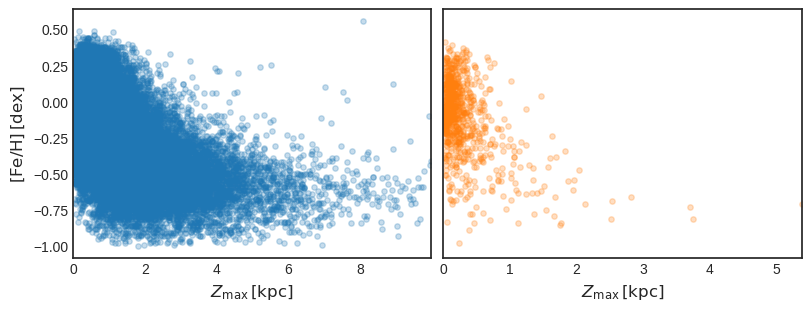

In [58]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

def plot_zmax_feh_two_panel(apogee, harps, bins=20, save_path=None):
    """
    Two-panel scatter plot:
    Left: APOGEE
    Right: HARPS

    apogee and harps must have columns:
        - 'zmax'
        - 'fe_h'
    """

    color_list_2 = ["#1f77b4", "#ff7f0e"]  # APOGEE, HARPS

    fig, axes = plt.subplots(1, 2, figsize=(8, 3), sharey=True, constrained_layout=True)

    datasets = [(apogee, "APOGEE", color_list_2[0]),
                (harps, "HARPS", color_list_2[1])]

    for ax, (df, label, color) in zip(axes, datasets):

        x = np.array(df.zmax)
        y = np.array(df.fe_h)

        ax.scatter(x, y, s=15, alpha=0.25, color=color)

        # Running median
        edges = np.linspace(x.min(), x.max(), bins + 1)
        centers = 0.5 * (edges[:-1] + edges[1:])
        medians, _, _ = binned_statistic(x, y, statistic="median", bins=edges)

        #ax.plot(centers, medians, color="black", lw=2)

        ax.set_xlabel(r"$Z_{\max}\,[\mathrm{kpc}]$")
        #ax.set_title(label)

        ax.set_xlim(0, np.percentile(x, 100))  # avoid extreme outliers

    axes[0].set_ylabel(r"$\mathrm{[Fe/H]}\,[\mathrm{dex}]$")

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

plot_zmax_feh_two_panel(apogee, harps,
                        bins=25,
                        save_path="zmax_feh_apogee_harps.png")

In [54]:
harps.describe()

,zmax,rperi,P_gal,eccentricity,rapo,V_lsr,W_lsr,UVW_lsr,U_lsr,fe_h
count,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000,798.000000
mean,0.313579,6.540597,88.666040,0.173874,9.184469,-15.835322,-1.603951,50.061291,2.013567,-0.114862
std,0.442458,1.377916,24.348994,0.125711,1.293732,34.874633,22.485251,37.768183,44.228712,0.259546
min,0.005405,0.232786,0.000000,0.003106,8.061570,-278.721564,-94.422747,3.486838,-234.291678,-0.980000
25%,0.082893,5.777214,94.200000,0.090015,8.282318,-29.062890,-13.279501,27.538492,-27.030970,-0.260000
50%,0.180089,6.884617,98.000000,0.143552,8.796066,-9.370920,-0.981304,41.628528,1.927270,-0.090000
75%,0.358660,7.575456,98.800000,0.224889,9.638354,3.378639,10.088298,62.466349,26.398063,0.070000
max,5.382480,8.159623,99.200000,0.977868,23.199260,53.866105,109.505391,384.496363,297.986984,0.410000


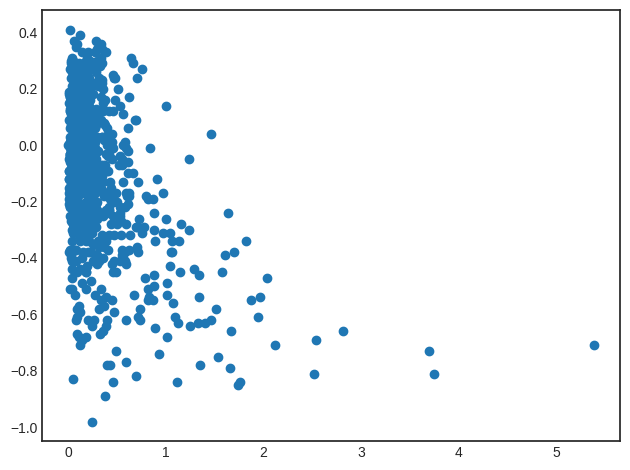

In [47]:
plt.scatter(harps.zmax, harps.fe_h)

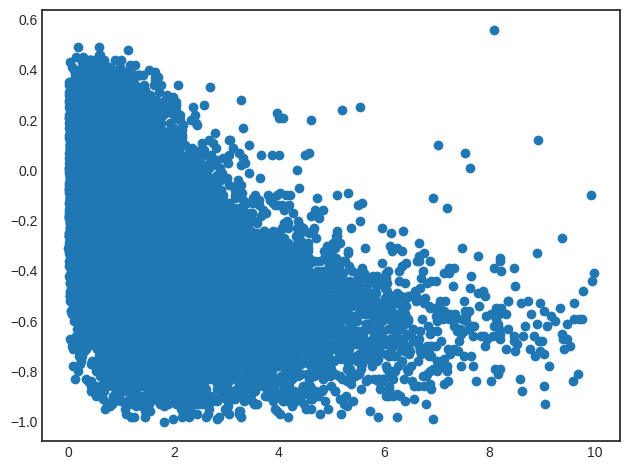

In [46]:
plt.scatter(apogee.zmax, apogee.fe_h)